In [1]:
import sys
import os

import h5py

from matplotlib import pyplot as plt

import numpy as np
import pandas as pd

from sklearn.decomposition import PCA


sys.path.append(os.path.join(os.getcwd(), '../../import/'))

# noinspection PyUnresolvedReferences
from utils import read_utils
# noinspection PyUnresolvedReferences
from utils import plot_utils
# noinspection PyUnresolvedReferences
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/Work/ZimmerLab/MSc_Thesis/Workspace/hobe/fly-2023-schaffner/data_exploration/manifold/../../import/utils/train_utils.py'>

In [3]:
# selection_n = ['DD01', 'VB02', 'SMDDR', 'AVAR']
selection_bhl = ['quiescence', 'ab_bending', 'grooming_b', 'grooming_f', 'running']

dims = 3
dims_preca = 5

read_ids = [20]
plot_id = 20

In [4]:
path = os.path.join(read_utils.get_data_path(), 'fly-2023-schaffner')
(file_ids, filenames,
 traces,
 ball_motions,
 behavioral_states) = read_utils.get_data(path, read_ids)

In [5]:
(modes_manifold, modes_manifold_b,
 recos_manifold, recos_manifold_b,
 loads_cca_man, loads_cca_man_b,
 vars_expl_mans, vars_expl_mans_rs) = train_utils.get_manifolds_cca(traces,
																	[bs[selection_bhl] for bs in behavioral_states],
																	n_cv=dims, n_pc=dims_preca)

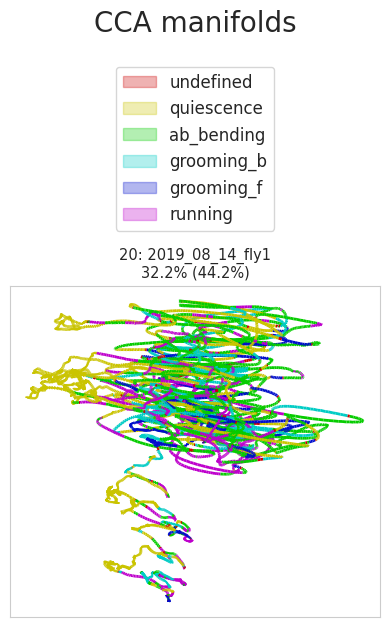

32.2% (22.1%)


In [9]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
						  modes_manifold, [bs[selection_bhl] for bs in behavioral_states],
						  [vx[:2] for vx in vars_expl_mans], [vx[:2] for vx in vars_expl_mans_rs] if dims_preca > 0 else None,
						  title='CCA manifolds', top_space=2.5)

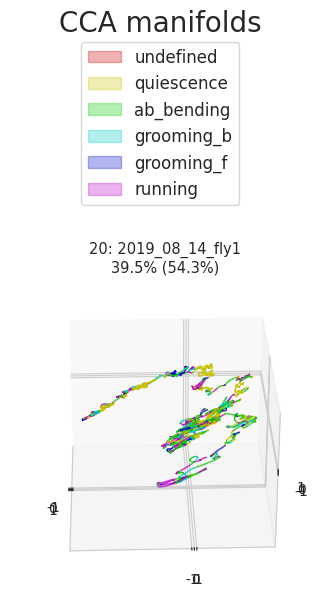

39.5% (18.1%)


In [10]:
plot_utils.plot_manifolds_3d_sep([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
								 modes_manifold, [bs[selection_bhl] for bs in behavioral_states],
								 [vx[:3] for vx in vars_expl_mans], [vx[:3] for vx in vars_expl_mans_rs] if dims_preca > 0 else None,
								 animate=True, n_plots=1,
								 titles=['CCA manifolds'] * len(file_ids), save_name=f'{f'{dims_preca}-dim-PCA_' if dims_preca > 0 else ''}{dims}-dim-CCA_3d')